In [1]:
import numpy as np
import matplotlib.pyplot as plt

--- PROBLEM 2: Bare Sphere k-effective ---
N =  10 | k_effective = 1.188333
N =  20 | k_effective = 1.187363
N =  50 | k_effective = 1.187090
N = 200 | k_effective = 1.187042
Analytical k (Problem 2): 1.187038
Problem 2(b) Critical nuSigf (Analytical): 0.155968 cm^-1



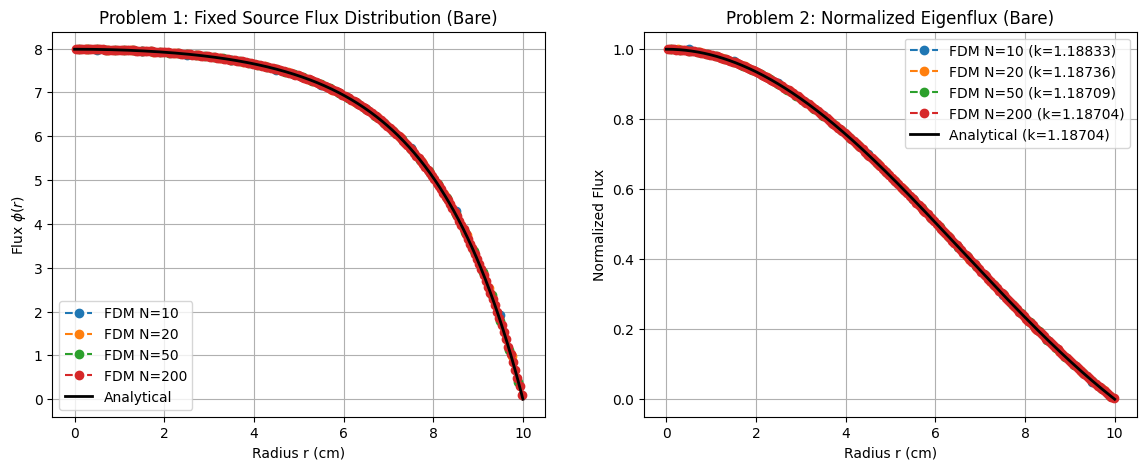

In [5]:
def pure_bisection(func, a, b, tol=1e-8, max_iter=100):
    fa, fb = func(a), func(b)
    if fa * fb > 0:
        raise ValueError(f"Root is not bracketed in [{a}, {b}]. f({a})={fa:.3e}, f({b})={fb:.3e}")
    for _ in range(max_iter):
        c = (a + b) / 2.0
        fc = func(c)
        if abs(fc) < tol or (b - a) / 2.0 < tol:
            return c
        if fa * fc < 0:
            b, fb = c, fc
        else:
            a, fa = c, fc
    return (a + b) / 2.0

Rc = 10.0          
Rr = 15.0            
D_c = 0.3543         
Siga_c = 0.121       
nuSigf_c = 0.18514  

D_r = 0.16           
Siga_r = 0.0197     
nuSigf_r = 0.0      

grids = [10, 20, 50, 200]  

Lc = np.sqrt(D_c / Siga_c)
Lr = np.sqrt(D_r / Siga_r)

def solve_fdm_spherical(R_max, N, D_arr, Siga_arr, nuSigf_arr, S_arr, is_eigenvalue=False):
    dr = R_max / N
    r_center = np.linspace(0.5 * dr, R_max - 0.5 * dr, N)
    r_edge = np.linspace(0, R_max, N + 1)
    
    A = np.zeros((N, N))
    M = np.zeros((N, N))
    
    for i in range(N):
        r_w = r_edge[i]      
        r_e = r_edge[i+1]    
        vol = (r_e**3 - r_w**3) / 3.0
        
        if i == 0:
            a_W = 0.0
        else:
            D_w = 2.0 * D_arr[i] * D_arr[i-1] / (D_arr[i] + D_arr[i-1])
            a_W = D_w * (r_w**2) / dr
            A[i, i-1] = -a_W
            
        if i == N - 1:
            a_E = D_arr[i] * (r_e**2) / (0.5 * dr)
        else:
            D_e = 2.0 * D_arr[i] * D_arr[i+1] / (D_arr[i] + D_arr[i+1])
            a_E = D_e * (r_e**2) / dr
            A[i, i+1] = -a_E
            
        A[i, i] = a_W + a_E + Siga_arr[i] * vol
        M[i, i] = nuSigf_arr[i] * vol

    if not is_eigenvalue:
        cell_volumes = (r_edge[1:]**3 - r_edge[:-1]**3) / 3.0
        phi = np.linalg.solve(A, S_arr * cell_volumes)
        return r_center, phi
    else:
        phi = np.ones(N)
        k = 1.0
        for _ in range(3000):
            phi_old = phi.copy()
            k_old = k
            fission_source = (1.0 / k_old) * np.dot(M, phi_old)
            phi = np.linalg.solve(A, fission_source)
            k = k_old * (np.max(phi) / np.max(phi_old))
            phi = phi / np.max(phi)
            if abs(k - k_old) < 1e-11:
                break
        return r_center, phi, k

def build_mesh_properties(N_total, R_outer):
    dr = R_outer / N_total
    r_center = np.linspace(0.5 * dr, R_outer - 0.5 * dr, N_total)
    
    D_a = np.where(r_center <= Rc, D_c, D_r)
    Siga_a = np.where(r_center <= Rc, Siga_c, Siga_r)
    nuSigf_a = np.where(r_center <= Rc, nuSigf_c, 0.0)
    S_a = np.where(r_center <= Rc, 1.0, 0.0)
    
    return D_a, Siga_a, nuSigf_a, S_a

fig1, ax1 = plt.subplots(1, 2, figsize=(14, 5))

for N in grids:
    D_a = np.full(N, D_c)
    Siga_a = np.full(N, Siga_c)
    S_a = np.full(N, 1.0)
    r_fd, phi_fd = solve_fdm_spherical(Rc, N, D_a, Siga_a, np.zeros(N), S_a)
    ax1[0].plot(r_fd, phi_fd, 'o--', label=f'FDM N={N}')

r_dense = np.linspace(1e-6, Rc, 500)
phi_ana_1 = (1.0 / Siga_c) * (1.0 - (Rc * np.sinh(r_dense / Lc)) / (r_dense * np.sinh(Rc / Lc)))
ax1[0].plot(r_dense, phi_ana_1, 'k-', linewidth=2, label='Analytical')
ax1[0].set_title('Problem 1: Fixed Source Flux Distribution (Bare)')
ax1[0].set_xlabel('Radius r (cm)')
ax1[0].set_ylabel('Flux $\phi(r)$')
ax1[0].legend()
ax1[0].grid(True)

print("--- PROBLEM 2: Bare Sphere k-effective ---")
for N in grids:
    D_a = np.full(N, D_c)
    Siga_a = np.full(N, Siga_c)
    nuSigf_a = np.full(N, nuSigf_c)
    r_fd, phi_fd, k_val = solve_fdm_spherical(Rc, N, D_a, Siga_a, nuSigf_a, np.zeros(N), is_eigenvalue=True)
    print(f"N = {N:3d} | k_effective = {k_val:.6f}")
    ax1[1].plot(r_fd, phi_fd, 'o--', label=f'FDM N={N} (k={k_val:.5f})')

B_sq = (np.pi / Rc)**2
k_ana_2 = nuSigf_c / (D_c * B_sq + Siga_c)
phi_ana_2 = np.sin(np.pi * r_dense / Rc) / (np.pi * r_dense / Rc)

ax1[1].plot(r_dense, phi_ana_2, 'k-', linewidth=2, label=f'Analytical (k={k_ana_2:.5f})')
ax1[1].set_title('Problem 2: Normalized Eigenflux (Bare)')
ax1[1].set_xlabel('Radius r (cm)')
ax1[1].set_ylabel('Normalized Flux')
ax1[1].legend()
ax1[1].grid(True)

nuSigf_crit_p2 = D_c * B_sq + Siga_c
print(f"Analytical k (Problem 2): {k_ana_2:.6f}")
print(f"Problem 2(b) Critical nuSigf (Analytical): {nuSigf_crit_p2:.6f} cm^-1\n")



--- PROBLEM 3: Reflected Sphere k-effective ---
N =  10 | k_effective = 1.373220
N =  20 | k_effective = 1.355697
N =  50 | k_effective = 1.357521
N = 200 | k_effective = 1.358795
Analytical k (Problem 3): 1.359271
Problem 3(b) Critical nuSigf (Analytical): 0.155968 cm^-1



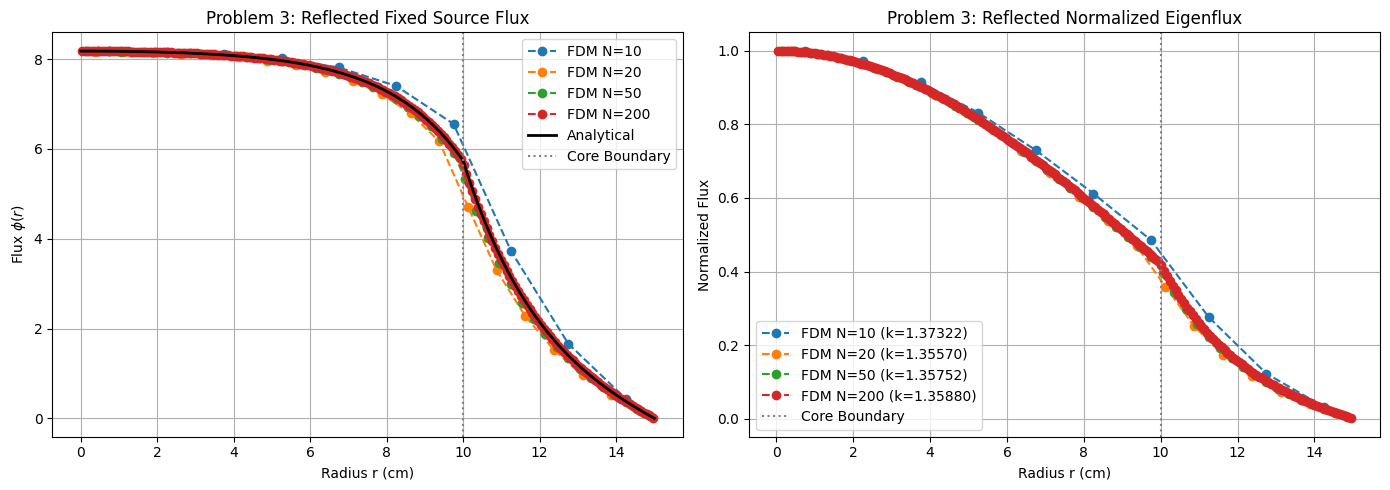

In [6]:
fig2, ax2 = plt.subplots(1, 2, figsize=(14, 5))

for N in grids:
    D_a, Siga_a, nuSigf_a, S_a = build_mesh_properties(N, Rr)
    r_fd, phi_fd = solve_fdm_spherical(Rr, N, D_a, Siga_a, nuSigf_a, S_a, is_eigenvalue=False)
    ax2[0].plot(r_fd, phi_fd, 'o--', label=f'FDM N={N}')

def analytical_reflected_fixed_source(r_vec):
    val_c = np.sinh(Rc / Lc) / Rc
    dval_c = ((Rc / Lc) * np.cosh(Rc / Lc) - np.sinh(Rc / Lc)) / (Rc**2)
    
    val_r = np.sinh((Rr - Rc) / Lr) / Rc
    dval_r = (- (Rc / Lr) * np.cosh((Rr - Rc) / Lr) - np.sinh((Rr - Rc) / Lr)) / (Rc**2)
    
    M_sys = np.array([
        [val_c, val_r],
        [D_c * dval_c, D_r * dval_r]
    ])
    rhs = np.array([1.0 / Siga_c, 0.0])
    
    C1, C2 = np.linalg.solve(M_sys, rhs)
    
    phi = np.zeros_like(r_vec)
    for idx, r in enumerate(r_vec):
        if r <= Rc:
            phi[idx] = (1.0 / Siga_c) - C1 * (np.sinh(r / Lc) / r)
        else:
            phi[idx] = C2 * (np.sinh((Rr - r) / Lr) / r)
    return phi

r_dense_ref = np.linspace(1e-5, Rr, 500)
ax2[0].plot(r_dense_ref, analytical_reflected_fixed_source(r_dense_ref), 'k-', linewidth=2, label='Analytical')
ax2[0].set_title('Problem 3: Reflected Fixed Source Flux')
ax2[0].set_xlabel('Radius r (cm)')
ax2[0].set_ylabel('Flux $\phi(r)$')
ax2[0].axvline(Rc, color='gray', linestyle=':', label='Core Boundary')
ax2[0].legend()
ax2[0].grid(True)

print("--- PROBLEM 3: Reflected Sphere k-effective ---")
for N in grids:
    D_a, Siga_a, nuSigf_a, S_a = build_mesh_properties(N, Rr)
    r_fd, phi_fd, k_val = solve_fdm_spherical(Rr, N, D_a, Siga_a, nuSigf_a, S_a, is_eigenvalue=True)
    print(f"N = {N:3d} | k_effective = {k_val:.6f}")
    ax2[1].plot(r_fd, phi_fd, 'o--', label=f'FDM N={N} (k={k_val:.5f})')

def critical_eq_k(k):
    val = (nuSigf_c / k - Siga_c) / D_c
    if val <= 0:
        return 1e5
    B = np.sqrt(val)
    lhs = D_c * (1.0 - B * Rc / np.tan(B * Rc))
    rhs = D_r * (1.0 + (Rc / Lr) / np.tanh((Rr - Rc) / Lr))
    return lhs - rhs

k_ana_3 = pure_bisection(critical_eq_k, 1.2, 1.5)

def critical_nuSigf_eq(nuSigf_val):
    val = (nuSigf_val - Siga_c) / D_c
    if val <= 0:
        return 1e5
    B = np.sqrt(val)
    lhs = D_c * (1.0 - B * Rc / np.tan(B * Rc))
    rhs = D_r * (1.0 + (Rc / Lr) / np.tanh((Rr - Rc) / Lr))
    return lhs - rhs

nuSigf_crit_p3 = pure_bisection(critical_nuSigf_eq, 0.1, 0.3)

print(f"Analytical k (Problem 3): {k_ana_3:.6f}")
print(f"Problem 3(b) Critical nuSigf (Analytical): {nuSigf_crit_p3:.6f} cm^-1\n")

ax2[1].set_title('Problem 3: Reflected Normalized Eigenflux')
ax2[1].set_xlabel('Radius r (cm)')
ax2[1].set_ylabel('Normalized Flux')
ax2[1].axvline(Rc, color='gray', linestyle=':', label='Core Boundary')
ax2[1].legend()
ax2[1].grid(True)

plt.tight_layout()
plt.show()